# Audio Time Perception Model: Roseboom et al. (2019) Extension

## Overview
This notebook implements the audio component of the time perception pipeline,
following the same principles as the visual model (visual_model.ipynb).

## Two modes

**Mode 1 — Before experiment (current)**
No human data available yet. The notebook runs self-calibration:
it estimates a scaling factor from the clip durations themselves
so predictions are in roughly the right range of seconds.
This lets you verify the pipeline is working and inspect predictions.

**Mode 2 — After experiment**
Human duration estimates are available in `data/labels/audio_perceived.csv`.
The notebook fits a proper linear regression against human data,
exactly matching the visual model calibration approach.

The notebook auto-detects which mode to use based on whether the labels file exists.


In [1]:
# ============================================================================
# SECTION 1: Imports
# ============================================================================

import os
import json
import warnings
from pathlib import Path
from typing import Dict, Tuple
from datetime import datetime

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import openl3

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

print(f"Python working directory: {os.getcwd()}")
print(f"OpenL3 version: {openl3.__version__}")


Python working directory: D:\Sahil\Capstone_Project\notebooks
OpenL3 version: 0.4.2


In [2]:
# ============================================================================
# SECTION 2: Configuration
# ============================================================================

PROJECT_ROOT  = Path.cwd().parent
AUDIO_ROOT    = PROJECT_ROOT / "data" / "processed"
OUT_DIR       = PROJECT_ROOT / "results" / "audio"
SEGMENTS_DIR  = OUT_DIR / "segments"
MODELS_DIR    = PROJECT_ROOT / "models"

for d in [OUT_DIR, SEGMENTS_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Audio extraction
TARGET_SR        = 48_000   # Hz — matches preprocessing pipeline
HOP_DURATION     = 0.5      # seconds between OpenL3 window centres

# Accumulator — identical parameters to visual model
ATTENTION  = 0.67
EMA_ALPHA  = 0.03
THRESH_K   = 0.4
REFRACTORY = 1
WARMUP     = 3

# Human labels (only needed for Mode 2 — after experiment)
LABELS_PATH = PROJECT_ROOT / "data" / "labels" / "audio_perceived.csv"
LABEL_COL   = "perceived_s"

print("Configuration loaded")
print(f"Audio directory : {AUDIO_ROOT}")
print(f"Output directory: {OUT_DIR}")
print(f"Labels file     : {'FOUND' if LABELS_PATH.exists() else 'NOT FOUND — running in self-calibration mode'}")


Configuration loaded
Audio directory : D:\Sahil\Capstone_Project\data\processed
Output directory: D:\Sahil\Capstone_Project\results\audio
Labels file     : FOUND


## Feature Extraction and Change Detection

OpenL3 processes audio in fixed windows and produces a 512-dim embedding per window.
We then compute L2 distance between consecutive embeddings, exactly as the visual
model computes L2 distance between consecutive AlexNet fc7 vectors.

In [3]:
# ============================================================================
# SECTION 3: OpenL3 Feature Extraction and Change Detection
# ============================================================================

def extract_openl3_embeddings(
    audio_path: Path,
    target_sr: int  = TARGET_SR,
    hop_size: float = HOP_DURATION,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Extract OpenL3 embeddings from a WAV file.
    Returns embeddings (n_segments x 512) and timestamps (n_segments,).
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        y, sr = librosa.load(str(audio_path), sr=target_sr, mono=True)

    embeddings, timestamps = openl3.get_audio_embedding(
        y, sr,
        content_type="env",
        embedding_size=512,
        hop_size=hop_size,
        verbose=False,
    )
    return embeddings, timestamps


def compute_change(embeddings: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute L2 and cosine distance between consecutive embeddings.
    Identical to compute_change() in visual_model.ipynb.
    """
    n = embeddings.shape[0]
    l2_dist  = np.zeros(n, dtype=np.float32)
    cos_dist = np.zeros(n, dtype=np.float32)

    if n <= 1:
        return l2_dist, cos_dist

    a    = embeddings[:-1]
    b    = embeddings[1:]
    diff = b - a

    l2_dist[1:] = np.linalg.norm(diff, axis=1)

    a_norm  = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)
    b_norm  = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-8)
    cos_sim = np.sum(a_norm * b_norm, axis=1)
    cos_dist[1:] = 1.0 - np.clip(cos_sim, -1.0, 1.0)

    return l2_dist, cos_dist


## Accumulator Model

Identical to the visual model accumulator.
Input: L2 distances between OpenL3 embeddings.
Output: tick count per clip.

    threshold(t) = μ(t) + 1.6 × σ(t)

A tick fires when the attention-weighted change exceeds this threshold,
subject to warmup (5 segments) and refractory (1 segment) constraints.

In [4]:
# ============================================================================
# SECTION 4: Accumulator Model (identical to visual model)
# ============================================================================

def accumulate_ticks(
    dist:       np.ndarray,
    attention:  float = ATTENTION,
    ema_alpha:  float = EMA_ALPHA,
    thresh_k:   float = THRESH_K,
    refractory: int   = REFRACTORY,
    warmup:     int   = WARMUP,
) -> int:
    """
    Count ticks when attention-weighted L2 change exceeds adaptive EMA threshold.
    Identical to accumulate_ticks() in visual_model.ipynb.
    """
    x = (attention * np.asarray(dist, dtype=np.float32)).copy()
    if len(x) > 0 and x[0] == 0:
        x = x[1:]
    if len(x) <= warmup:
        return 0

    mu    = 0.0
    v     = 1e-6
    ticks = 0
    refr  = 0

    for t, xi in enumerate(x):
        xi        = float(xi)
        sigma     = float(np.sqrt(max(v, 1e-8)))
        threshold = mu + thresh_k * sigma

        if t >= warmup:
            if refr > 0:
                refr -= 1
            elif xi > threshold:
                ticks += 1
                refr   = int(refractory)

        prev_mu = mu
        mu = (1.0 - ema_alpha) * mu + ema_alpha * xi
        v  = (1.0 - ema_alpha) * v  + ema_alpha * (xi - prev_mu) * (xi - mu)

    return int(ticks)


In [5]:
# ============================================================================
# SECTION 5: Run Full Extraction Pipeline
# ============================================================================

def process_clip(audio_path: Path) -> Dict:
    """Extract embeddings, compute change, count ticks for one clip."""
    clip_id = audio_path.stem

    embeddings, timestamps = extract_openl3_embeddings(audio_path)

    if len(embeddings) == 0:
        return {"clip_id": clip_id, "ticks": 0, "duration_s": 0.0,
                "n_segments": 0, "mean_l2": np.nan, "sum_l2": np.nan}

    l2_dist, cos_dist = compute_change(embeddings)
    ticks              = accumulate_ticks(l2_dist)
    duration_s         = float(timestamps[-1]) if len(timestamps) > 0 else 0.0

    # Save per-segment data for inspection
    seg_df = pd.DataFrame({
        "time_s":      timestamps,
        "l2_to_prev":  l2_dist,
        "cos_to_prev": cos_dist,
    })
    seg_df.to_csv(SEGMENTS_DIR / f"{clip_id}_segments.csv", index=False)

    return {
        "clip_id":    clip_id,
        "ticks":      int(ticks),
        "n_segments": int(len(timestamps)),
        "duration_s": duration_s,
        "mean_l2":    float(np.nanmean(l2_dist)),
        "std_l2":     float(np.nanstd(l2_dist)),
        "sum_l2":     float(np.nansum(l2_dist)),
        "mean_cos":   float(np.nanmean(cos_dist)),
    }


# Run across all processed WAV files
audio_files = sorted(AUDIO_ROOT.rglob("*.wav"))
print(f"Found {len(audio_files)} WAV file(s)")

summaries = []
for audio_path in audio_files:
    print(f"  {audio_path.name} ...", end=" ")
    result = process_clip(audio_path)
    summaries.append(result)
    print(f"ticks={result['ticks']}, duration={result['duration_s']:.1f}s")

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(OUT_DIR / "summary.csv", index=False)
print(f"\nSummary saved: {OUT_DIR / 'summary.csv'}")
summary_df


Found 36 WAV file(s)
  10_processed.wav ... ticks=19, duration=22.5s
  11_processed.wav ... ticks=23, duration=24.5s
  12_processed.wav ... ticks=20, duration=21.5s
  13_processed.wav ... ticks=21, duration=22.5s
  14_processed.wav ... WARNING:tensorflow:5 out of the last 9 calls to <function Model.make_predict_function.<locals>.predict_function at 0x0000017901CEBB80> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
ticks=18, duration=20.0s
  15_processed.wav ... WARNING:tensor

,clip_id,ticks,n_segments,duration_s,mean_l2,std_l2,sum_l2,mean_cos
0,10_processed,19,46,22.5,6.339386,3.318385,291.611755,0.008858
1,11_processed,23,50,24.5,5.740616,1.434741,287.030792,0.006522
2,12_processed,20,44,21.5,6.191154,2.746087,272.410797,0.008070
3,13_processed,21,46,22.5,7.704391,2.779163,354.401978,0.010120
4,14_processed,18,41,20.0,7.609491,2.463974,311.989136,0.009785
5,15_processed,16,36,17.5,6.902871,2.889056,248.503357,0.008923
6,16_processed,24,53,26.0,7.172189,2.166545,380.126007,0.008438
7,17_processed,19,44,21.5,6.632895,2.456591,291.847351,0.008643
8,18_processed,20,49,24.0,6.979296,2.894779,341.985504,0.009210
9,19_processed,19,50,24.5,6.679023,3.480332,333.951172,0.009617


## Calibration

**Mode 1 (no human data):** Self-calibration
The notebook estimates a scaling factor from the clips themselves.
It finds the median rate of ticks per second across all clips and inverts it:
`slope = 1 / median_rate`. This puts predictions roughly in the right range
of seconds so you can inspect whether the pipeline is working.
`intercept = 0` in self-calibration mode.

**Mode 2 (human data available):** Supervised calibration
Fits `perceived_duration = slope × ticks + intercept` against real human estimates.
This is the final calibration used for the actual results.

The notebook detects which mode to use automatically.


In [6]:
# ============================================================================
# SECTION 6: Calibration — auto-detects Mode 1 or Mode 2
# ============================================================================

def calibrate(summary_df: pd.DataFrame) -> pd.DataFrame:
    df = summary_df.copy()

    if LABELS_PATH.exists():
        print("Human labels found — running supervised calibration (Mode 2)")
        labels_df = pd.read_csv(LABELS_PATH)

        # Normalise clip_id to plain integer string in both dataframes
        df["clip_id"] = df["clip_id"].astype(str).str.replace("_processed", "").str.strip()
        labels_df["clip_id"] = labels_df["clip_id"].astype(str).str.strip()

        df = df.merge(labels_df[["clip_id", LABEL_COL]], on="clip_id", how="inner")
        df = df.dropna(subset=["ticks", LABEL_COL])

        X = df[["ticks"]].values.reshape(-1, 1)
        y = df[LABEL_COL].values

        lr = LinearRegression()
        lr.fit(X, y)

        slope     = float(lr.coef_[0])
        intercept = float(lr.intercept_)
        method    = "supervised"

        r   = float(pearsonr(lr.predict(X), y)[0])
        mae = float(np.abs(lr.predict(X) - y).mean())
        print(f"  Pearson r with human estimates: {r:.3f}")
        print(f"  MAE: {mae:.2f}s")
        print(f"  Clips matched: {len(df)}")

    else:
        # Mode 1 — self calibration
        print(f"No human labels found at {LABELS_PATH}")
        valid = df[(df["duration_s"] > 0) & (df["ticks"] > 0)].copy()
        valid["ticks_per_sec"] = valid["ticks"] / valid["duration_s"]
        median_rate = float(np.median(valid["ticks_per_sec"]))
        slope     = 1.0 / median_rate if median_rate > 0 else 1.0
        intercept = 0.0
        method    = "self"
        r         = None
        mae       = None
        print(f"  Self-calibrated slope: {slope:.4f} s/tick")

    df["pred_perceived_s"] = slope * df["ticks"] + intercept
    print(f"Calibration: perceived_duration = {slope:.4f} x ticks + {intercept:.4f}")

    artifact = {
        "name":       "audio_accumulator_openl3",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "mode":       method,
        "params": {
            "ATTENTION":  float(ATTENTION),
            "EMA_ALPHA":  float(EMA_ALPHA),
            "THRESH_K":   float(THRESH_K),
            "REFRACTORY": int(REFRACTORY),
            "WARMUP":     int(WARMUP),
        },
        "calibration": {
            "slope":     slope,
            "intercept": intercept,
        },
        "metrics": {
            "pearson_r_vs_human": r,
            "mae_vs_human":       mae,
        },
    }

    for p in [OUT_DIR / "calibration.json",
              MODELS_DIR / "audio_accumulator_latest.json",
              MODELS_DIR / f"audio_accumulator_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"]:
        with open(p, "w") as f:
            json.dump(artifact, f, indent=2)

    print(f"Artifact saved: {MODELS_DIR / 'audio_accumulator_latest.json'}")
    return df


result_df = calibrate(summary_df)
result_df[["clip_id", "duration_s", "ticks", "pred_perceived_s"]]


Human labels found — running supervised calibration (Mode 2)
  Pearson r with human estimates: 0.690
  MAE: 2.40s
  Clips matched: 36
Calibration: perceived_duration = 0.7326 x ticks + 4.4314
Artifact saved: D:\Sahil\Capstone_Project\models\audio_accumulator_latest.json


,clip_id,duration_s,ticks,pred_perceived_s
0,10,22.5,19,18.350938
1,11,24.5,23,21.281366
2,12,21.5,20,19.083545
3,13,22.5,21,19.816152
4,14,20.0,18,17.618331
5,15,17.5,16,16.153116
6,16,26.0,24,22.013973
7,17,21.5,19,18.350938
8,18,24.0,20,19.083545
9,19,24.5,19,18.350938


AUDIO MODEL PREDICTIONS
Clip                             Duration    Ticks    Predicted
------------------------------------------------------------
24                                  16.0s       15       15.42s
31                                  17.0s       16       16.15s
22                                  17.0s       16       16.15s
15                                  17.5s       16       16.15s
23                                  18.5s       17       16.89s
9                                   19.0s       16       16.15s
20                                  19.0s       18       17.62s
21                                  19.5s       18       17.62s
33                                  20.0s       17       16.89s
14                                  20.0s       18       17.62s
27                                  20.5s       18       17.62s
12                                  21.5s       20       19.08s
30                                  21.5s       20       19.08s
17                 

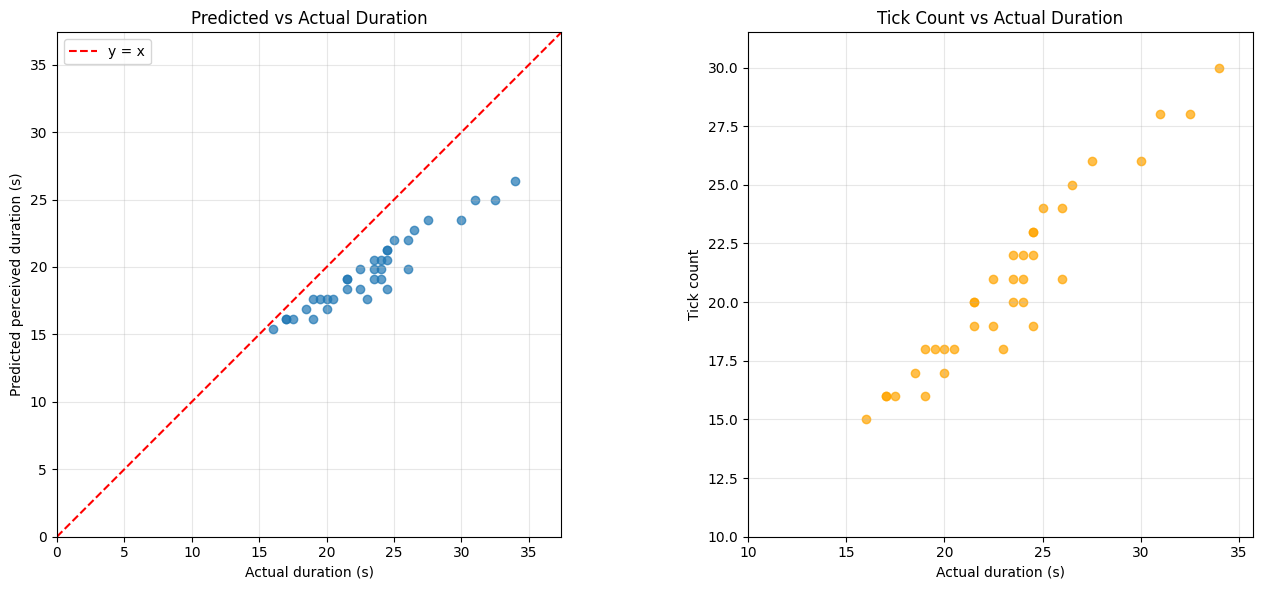

Plot saved: D:\Sahil\Capstone_Project\results\audio\audio_predictions.png


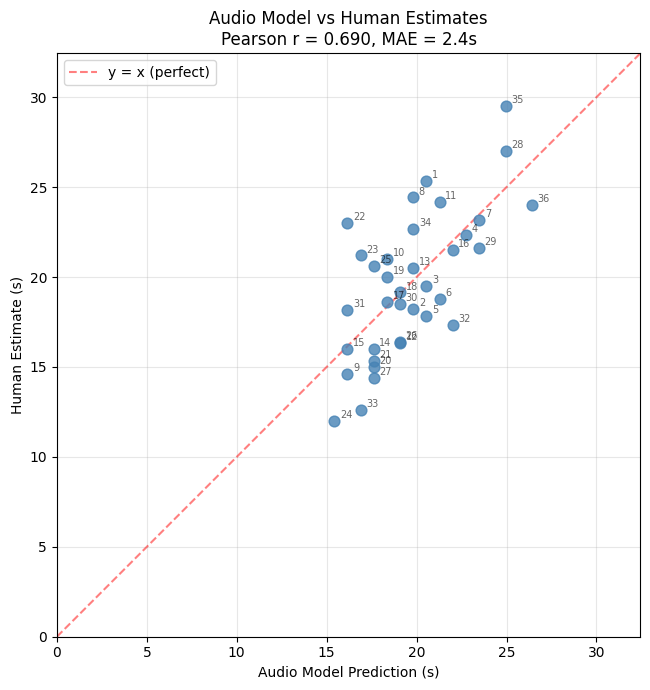


Audio model vs human estimates:
  Clips matched: 36
  Pearson r:     0.690
  MAE:           2.40s
  Plot saved:    D:\Sahil\Capstone_Project\results\audio\audio_vs_human.png


In [7]:
# ============================================================================
# SECTION 7: Inspect Predictions
# ============================================================================

# ── 1. Print table ───────────────────────────────────────────────────────────
print("=" * 60)
print("AUDIO MODEL PREDICTIONS")
print("=" * 60)
print(f"{'Clip':<30} {'Duration':>10} {'Ticks':>8} {'Predicted':>12}")
print("-" * 60)
for _, row in result_df.sort_values("duration_s").iterrows():
    print(f"{row['clip_id']:<30} {row['duration_s']:>9.1f}s {int(row['ticks']):>8} {row['pred_perceived_s']:>11.2f}s")
print()
print(f"Mode: {'Supervised (human labels)' if LABELS_PATH.exists() else 'Self-calibrated'}")
print(f"N clips processed:       {len(result_df)}")
print(f"Mean predicted duration: {result_df['pred_perceived_s'].mean():.2f}s")
print(f"Mean actual duration:    {result_df['duration_s'].mean():.2f}s")

# ── 2. Predicted vs Actual Duration ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1 — predicted vs actual (equal axes)
all_vals_1  = pd.concat([result_df["duration_s"], result_df["pred_perceived_s"]])
axis_max_1  = all_vals_1.max() * 1.1
axes[0].scatter(result_df["duration_s"], result_df["pred_perceived_s"], alpha=0.7)
axes[0].plot([0, axis_max_1], [0, axis_max_1], "r--", label="y = x")
axes[0].set_xlim(0, axis_max_1)
axes[0].set_ylim(0, axis_max_1)
axes[0].set_aspect("equal")
axes[0].set_xlabel("Actual duration (s)")
axes[0].set_ylabel("Predicted perceived duration (s)")
axes[0].set_title("Predicted vs Actual Duration")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2 — tick count vs actual duration (no equal axes needed, different units)
axes[1].scatter(result_df["duration_s"], result_df["ticks"], alpha=0.7, color="orange")
axes[1].set_xlim(10, result_df["duration_s"].max() * 1.05)
axes[1].set_ylim(10, result_df["ticks"].max() * 1.05)
axes[1].set_box_aspect(1)
axes[1].set_xlabel("Actual duration (s)")
axes[1].set_ylabel("Tick count")
axes[1].set_title("Tick Count vs Actual Duration")
axes[1].grid(alpha=0.3)


plt.tight_layout()
plt.savefig(OUT_DIR / "audio_predictions.png", dpi=150)
plt.show()
print(f"Plot saved: {OUT_DIR / 'audio_predictions.png'}")

# ── 3. Predictions vs Human Estimates ───────────────────────────────────────
if LABELS_PATH.exists():
    labels_df = pd.read_csv(LABELS_PATH)
    labels_df["clip_id"] = labels_df["clip_id"].astype(str).str.strip()
    result_df["clip_id_clean"] = result_df["clip_id"].astype(str).str.replace("_processed", "").str.strip()

    merged = result_df.merge(labels_df[["clip_id", "perceived_s"]],
                             left_on="clip_id_clean", right_on="clip_id", how="inner")

    if len(merged) > 0:
        r   = pearsonr(merged["pred_perceived_s"], merged["perceived_s_y"])[0]
        mae = np.abs(merged["pred_perceived_s"] - merged["perceived_s_y"]).mean()

        fig2, ax = plt.subplots(figsize=(7, 7))
        ax.scatter(merged["pred_perceived_s"], merged["perceived_s_y"],
                   alpha=0.8, color="steelblue", s=60, zorder=3)
        for _, row in merged.iterrows():
            ax.annotate(str(row["clip_id_clean"]),
                        (row["pred_perceived_s"], row["perceived_s_y"]),
                        fontsize=7, alpha=0.6, textcoords="offset points", xytext=(4, 2))

        all_vals_2 = pd.concat([merged["pred_perceived_s"], merged["perceived_s_y"]])
        axis_max_2 = all_vals_2.max() * 1.1
        ax.set_xlim(0, axis_max_2)
        ax.set_ylim(0, axis_max_2)
        ax.set_aspect("equal")
        ax.plot([0, axis_max_2], [0, axis_max_2], "r--", alpha=0.5, label="y = x (perfect)")
        ax.set_xlabel("Audio Model Prediction (s)")
        ax.set_ylabel("Human Estimate (s)")
        ax.set_title(f"Audio Model vs Human Estimates\nPearson r = {r:.3f}, MAE = {mae:.1f}s")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUT_DIR / "audio_vs_human.png", dpi=150)
        plt.show()

        print(f"\nAudio model vs human estimates:")
        print(f"  Clips matched: {len(merged)}")
        print(f"  Pearson r:     {r:.3f}")
        print(f"  MAE:           {mae:.2f}s")
        print(f"  Plot saved:    {OUT_DIR / 'audio_vs_human.png'}")
    else:
        print("No matching clips between predictions and human labels.")

## Notes

### Running modes

| Situation | What happens |
|---|---|
| No `audio_perceived.csv` yet | Self-calibration — slope = 1 / median tick rate, intercept = 0 |
| `audio_perceived.csv` exists | Supervised calibration — linear regression against human estimates |

To switch from Mode 1 to Mode 2, just place your labels file at
`data/labels/audio_perceived.csv` with columns `clip_id` and `perceived_s`,
then re-run the notebook from Section 6 onwards.

### Comparison with visual model

| | Visual model | Audio model |
|---|---|---|
| Feature extractor | AlexNet fc7 (4096-dim) | OpenL3 (512-dim) |
| Input | Video frames at 30 fps | Audio windows, 0.5s hop |
| Change metric | L2 between fc7 vectors | L2 between OpenL3 embeddings |
| Accumulator | EMA threshold + ticks | Identical |
| Calibration | Linear regression on ticks | Identical |
| Self-calibration fallback | No | Yes (Mode 1) |
